# args.me Corpus Exploration & Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)

This notebook explores the [`webis/args_me`](https://huggingface.co/datasets/webis/args_me) debate dataset, designed to run both locally and seamlessly inside **Google Colab**.

In [1]:
# 1. Environment Setup (Detects Google Colab vs Local)
import sys
import os

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')

if IN_COLAB:
    print("Running inside Google Colab!")
    !pip install -q datasets huggingface_hub pandas pyarrow matplotlib seaborn
    # Optional: Mount Google Drive if you want persistent storage
    # from google.colab import drive
    # drive.mount('/content/drive')
else:
    print("Running in local environment.")

Running inside Google Colab!


In [2]:
# 2. Imports and Configuration
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

DATASET_URL = "https://huggingface.co/datasets/webis/args_me/resolve/main/args-me.jsonl"
print("Configured dataset URL:", DATASET_URL)

Configured dataset URL: https://huggingface.co/datasets/webis/args_me/resolve/main/args-me.jsonl


In [3]:
# 3. Stream a sample from webis/args_me
# Using streaming=True loads records on the fly without downloading the entire ~850MB file
print("Connecting to args-me stream...")
ds_stream = load_dataset("json", data_files=DATASET_URL, split="train", streaming=True)

sample_records = []
NUM_RECORDS = 500

for idx, item in enumerate(ds_stream):
    if idx >= NUM_RECORDS:
        break
    sample_records.append(item)

print(f"Loaded {len(sample_records)} raw debate argument records.")

Connecting to args-me stream...
Loaded 500 raw debate argument records.


In [4]:
# 4. Flatten records into premise-level DataFrame
rows = []
for item in sample_records:
    arg_id = item.get("id", "")
    conclusion = item.get("conclusion", "")
    ctx = item.get("context", {}) or {}
    source_title = ctx.get("sourceTitle", "")
    discussion_title = ctx.get("discussionTitle", "")

    for p_idx, p in enumerate(item.get("premises", [])):
        rows.append({
            "arg_id": arg_id,
            "premise_idx": p_idx,
            "conclusion": conclusion,
            "stance": p.get("stance", "UNKNOWN"),
            "text": p.get("text", ""),
            "discussion_title": discussion_title,
            "source_title": source_title,
            "word_count": len(p.get("text", "").split())
        })

df = pd.DataFrame(rows)
print(f"Total premise instances: {len(df)}")
df.head()

Total premise instances: 500


,arg_id,premise_idx,conclusion,stance,text,discussion_title,source_title,word_count
0,c67482ba-2019-04-18T13:32:05Z-00000-000,0,Contraceptive Forms for High School Students,CON,My opponent forfeited every round. None of my ...,Contraceptive Forms for High School Students,Debate Argument: Contraceptive Forms for High ...,90
1,c67482ba-2019-04-18T13:32:05Z-00001-000,0,Contraceptive Forms for High School Students,CON,How do you propose the school will fund your p...,Contraceptive Forms for High School Students,Debate Argument: Contraceptive Forms for High ...,84
2,c67482ba-2019-04-18T13:32:05Z-00002-000,0,Contraceptive Forms for High School Students,CON,Schools have no compelling interest in providi...,Contraceptive Forms for High School Students,Debate Argument: Contraceptive Forms for High ...,70
3,c67482ba-2019-04-18T13:32:05Z-00003-000,0,Contraceptive Forms for High School Students,PRO,As a senior at my school. My group and I are f...,Contraceptive Forms for High School Students,Debate Argument: Contraceptive Forms for High ...,82
4,4d3d4471-2019-04-18T11:45:01Z-00000-000,0,Australia should be a more significant country,CON,The resolution used by Pro *assumes* that Aust...,Australia should be a more significant country,Debate Issue: Australia should be a more signi...,301


Stance breakdown:
stance
CON    254
PRO    246
Name: count, dtype: int64


/tmp/ipykernel_1368/3327539933.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="stance", palette="viridis")


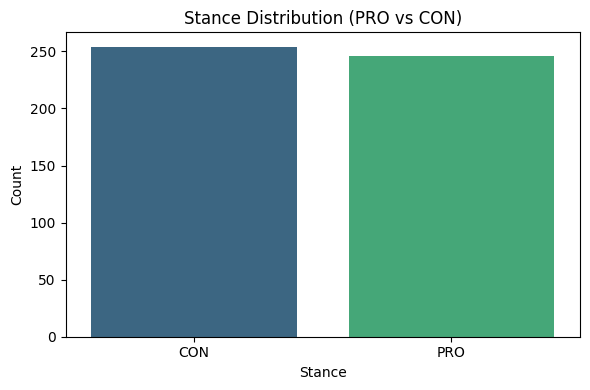

In [5]:
# 5. Stance Distribution
print("Stance breakdown:")
print(df["stance"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="stance", palette="viridis")
plt.title("Stance Distribution (PRO vs CON)")
plt.ylabel("Count")
plt.xlabel("Stance")
plt.tight_layout()
plt.show()

count     500.00000
mean      334.83200
std       411.09066
min         1.00000
25%        36.75000
50%       138.00000
75%       464.25000
max      1927.00000
Name: word_count, dtype: float64


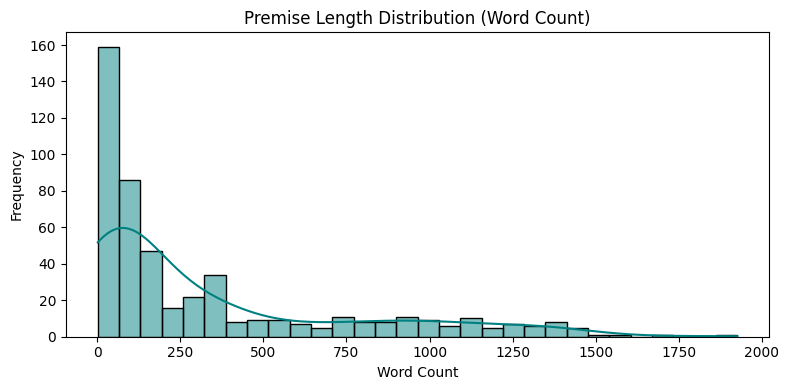

In [6]:
# 6. Premise Word Count Distribution
print(df["word_count"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df["word_count"], bins=30, kde=True, color="teal")
plt.title("Premise Length Distribution (Word Count)")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()